<a href="https://colab.research.google.com/github/vinayaksr06/vinayaksr06/blob/main/activity1_multiple_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import statsmodels
from scipy import stats
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")

print("=== Library Versions ===")
print(f"Python: {sys.version.split()[0]} | NumPy: {np.__version__} | Pandas: {pd.__version__} | Sklearn: {sklearn.__version__} | Statsmodels: {statsmodels.__version__}")

# Load dataset in unscaled physical units and save CSV copy
diabetes = load_diabetes(as_frame=True, scaled=False)
df = diabetes.frame.copy()
df.to_csv("diabetes_dataset.csv", index=False)

print(f"\nDataset Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:", df.isnull().sum().sum(), "| Duplicate rows:", df.duplicated().sum())
print("\nSummary Statistics (with Range):")
summary = df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]
summary['range'] = summary['max'] - summary['min']
display(summary.round(3))

=== Library Versions ===
Python: 3.13.18 | NumPy: 2.4.6 | Pandas: 2.2.3 | Sklearn: 1.6.1 | Statsmodels: 0.15.0

Dataset Shape: 442 rows x 11 columns

First 5 rows:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0



Missing values: 0 | Duplicate rows: 0

Summary Statistics (with Range):


,count,mean,std,min,50%,max,range
age,442.0,48.518,13.109,19.000,50.00,79.000,60.000
sex,442.0,1.468,0.500,1.000,1.00,2.000,1.000
bmi,442.0,26.376,4.418,18.000,25.70,42.200,24.200
bp,442.0,94.647,13.831,62.000,93.00,133.000,71.000
s1,442.0,189.140,34.608,97.000,186.00,301.000,204.000
s2,442.0,115.439,30.413,41.600,113.00,242.400,200.800
s3,442.0,49.788,12.934,22.000,48.00,99.000,77.000
s4,442.0,4.070,1.290,2.000,4.00,9.090,7.090
s5,442.0,4.641,0.522,3.258,4.62,6.107,2.849
s6,442.0,91.260,11.496,58.000,91.00,124.000,66.000


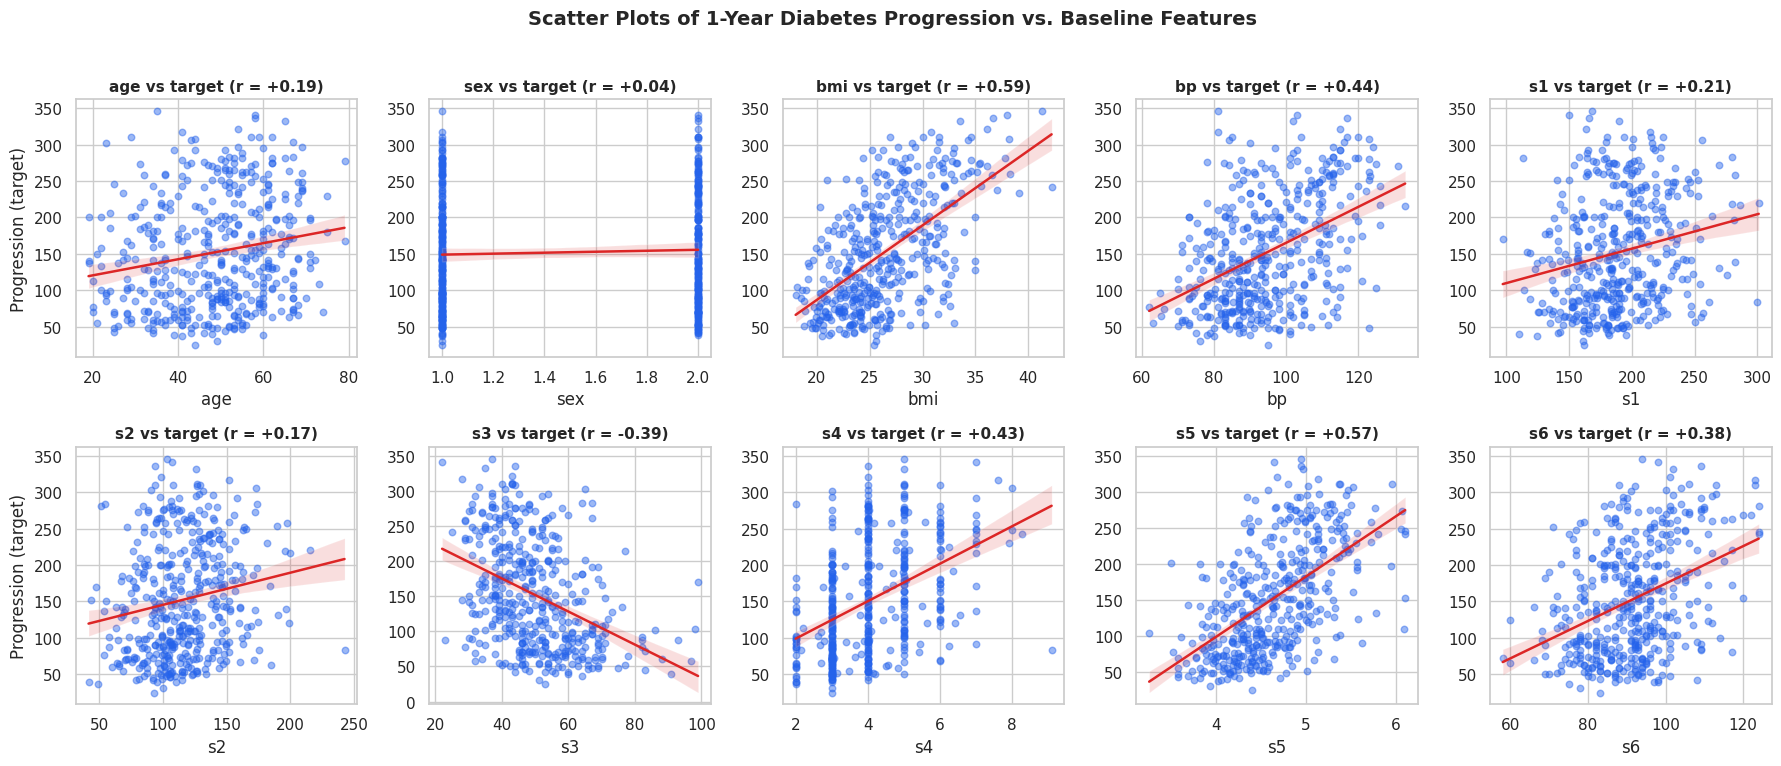

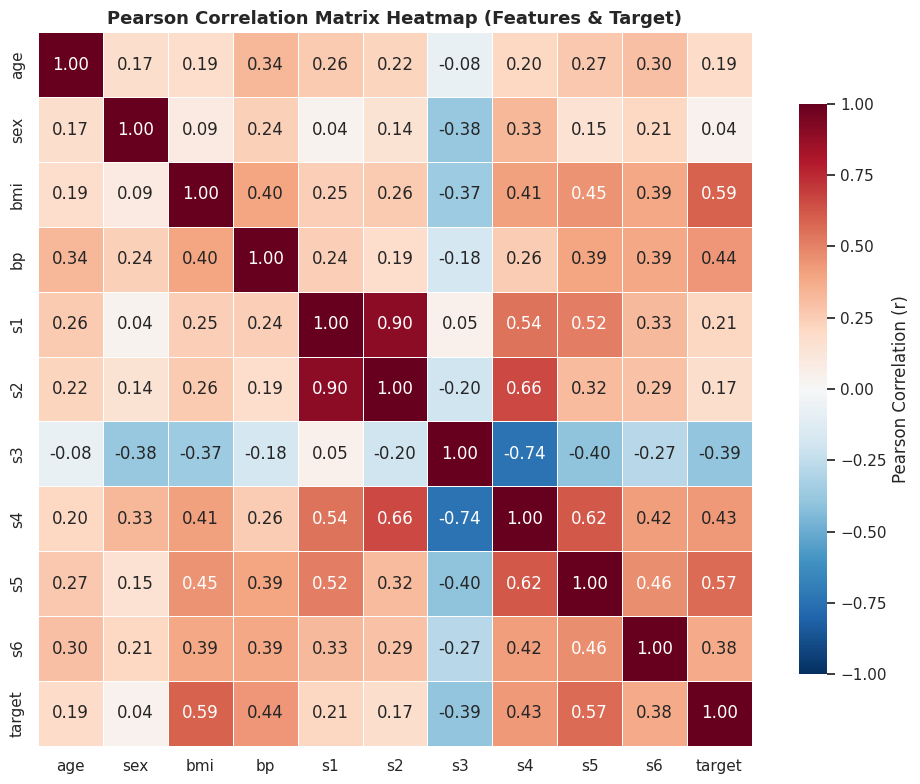

=== Feature-Target Correlations (Sorted) ===
bmi    0.5865
s5     0.5659
bp     0.4415
s4     0.4305
s6     0.3825
s1     0.2120
age    0.1879
s2     0.1741
sex    0.0431
s3    -0.3948
Name: target, dtype: float64

=== Strong Feature-Feature Correlations (|r| >= 0.60) ===
  s1 <-> s2 : r = +0.8967
  s2 <-> s4 : r = +0.6598
  s3 <-> s4 : r = -0.7385
  s4 <-> s5 : r = +0.6179


In [2]:
features = [c for c in df.columns if c != 'target']

# 1. Scatter plots of target vs each feature
fig, axes = plt.subplots(2, 5, figsize=(18, 7.5))
axes = axes.flatten()

for idx, col in enumerate(features):
    ax = axes[idx]
    r_val = df[col].corr(df['target'])
    sns.regplot(
        x=df[col], y=df['target'], ax=ax,
        scatter_kws={'alpha': 0.45, 's': 22, 'color': '#2563eb'},
        line_kws={'color': '#dc2626', 'linewidth': 1.8}
    )
    ax.set_title(f"{col} vs target (r = {r_val:+.2f})", fontsize=11, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel("Progression (target)" if idx % 5 == 0 else "")

fig.suptitle("Scatter Plots of 1-Year Diabetes Progression vs. Baseline Features", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 2. Correlation matrix heatmap
corr_matrix = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
    vmin=-1, vmax=1, square=True, linewidths=0.6,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation (r)"}
)
plt.title("Pearson Correlation Matrix Heatmap (Features & Target)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("=== Feature-Target Correlations (Sorted) ===")
print(corr_matrix['target'].drop('target').sort_values(ascending=False).round(4))

print("\n=== Strong Feature-Feature Correlations (|r| >= 0.60) ===")
fcorr = df[features].corr()
for i in range(len(features)):
    for j in range(i + 1, len(features)):
        val = fcorr.iloc[i, j]
        if abs(val) >= 0.60:
            print(f"  {features[i]} <-> {features[j]} : r = {val:+.4f}")

In [3]:
# Programmatic verification of Step 4 Manual Calculation vs. scikit-learn
sample_df = df[['bmi', 'bp', 'target']].iloc[:6].copy()

X_mat = np.column_stack([np.ones(len(sample_df)), sample_df['bmi'].values, sample_df['bp'].values])
y_vec = sample_df['target'].values

XtX = X_mat.T @ X_mat
Xty = X_mat.T @ y_vec
b_manual = np.linalg.inv(XtX) @ Xty

# Fit scikit-learn LinearRegression on the exact same 6 rows
lr_sample = LinearRegression().fit(sample_df[['bmi', 'bp']], sample_df['target'])
b_sklearn = np.array([lr_sample.intercept_, lr_sample.coef_[0], lr_sample.coef_[1]])

verify_df = pd.DataFrame({
    'Parameter': ['b0 (Intercept)', 'b1 (bmi)', 'b2 (bp)'],
    'Manual Normal Equations': b_manual,
    'Scikit-Learn OLS': b_sklearn,
    'Absolute Difference': np.abs(b_manual - b_sklearn)
})
display(verify_df)

y_hat_1 = b_manual[0] + b_manual[1] * sample_df['bmi'].iloc[0] + b_manual[2] * sample_df['bp'].iloc[0]
print(f"Obs 1 -> Actual: {sample_df['target'].iloc[0]:.2f} | Predicted: {y_hat_1:.4f} | Residual: {sample_df['target'].iloc[0] - y_hat_1:.4f}")

,Parameter,Manual Normal Equations,Scikit-Learn OLS,Absolute Difference
0,b0 (Intercept),130.730038,130.730038,1.421085e-13
1,b1 (bmi),5.958688,5.958688,2.664535e-14
2,b2 (bp),-1.628059,-1.628059,4.396483e-14


Obs 1 -> Actual: 151.00 | Predicted: 157.5700 | Residual: -6.5700


Training set: 353 rows (79.9%)
Testing set : 89 rows (20.1%)

=== Single-Feature Baseline (bmi) ===
Intercept : -131.8738
Slope bmi : 10.7628
Test R^2  : 0.2334

=== Full Multiple LR (All 10 Features) ===
Raw Intercept          : -341.3782
Standardized Intercept : 153.7365 (equals y_train mean)


,Feature,Raw Coefficient (per 1 unit),Standardized Coef (per 1 SD)
4,s1,-1.2817,-44.4489
8,s5,67.1090,35.1612
2,bmi,5.8464,25.6071
5,s2,0.8112,24.6410
3,bp,1.1971,16.8289
7,s4,10.1595,13.1388
1,sex,-23.0645,-11.5118
6,s3,0.6017,7.6770
9,s6,0.2016,2.3514
0,age,0.1377,1.7538


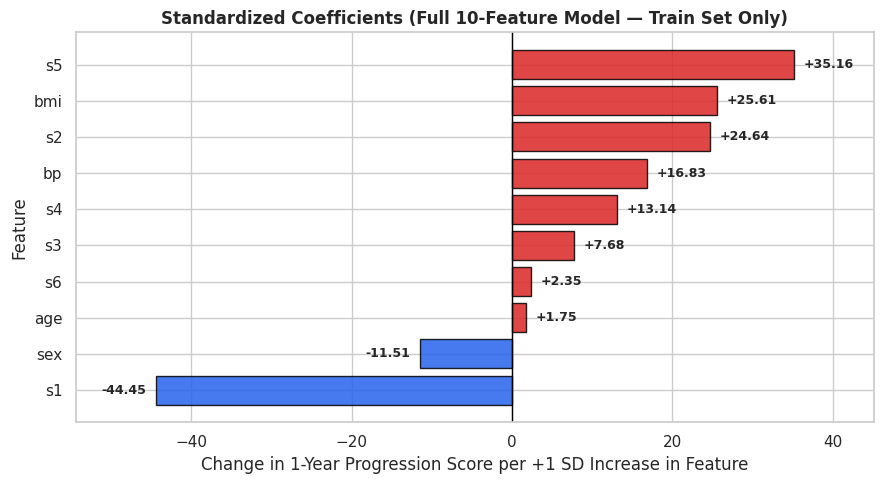

In [4]:
# 80:20 Train-Test Split
X = df[features]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Training set: {X_train.shape[0]} rows ({X_train.shape[0]/len(df)*100:.1f}%)")
print(f"Testing set : {X_test.shape[0]} rows ({X_test.shape[0]/len(df)*100:.1f}%)")

# 1. Mean Baseline
y_train_mean = y_train.mean()
y_pred_mean = np.full(shape=len(y_test), fill_value=y_train_mean)

# 2. Single-Feature Baseline (bmi — highest correlation with target)
lr_single = LinearRegression().fit(X_train[['bmi']], y_train)
y_pred_single = lr_single.predict(X_test[['bmi']])

print("\n=== Single-Feature Baseline (bmi) ===")
print(f"Intercept : {lr_single.intercept_:.4f}")
print(f"Slope bmi : {lr_single.coef_[0]:.4f}")
print(f"Test R^2  : {r2_score(y_test, y_pred_single):.4f}")

# 3. Full Multiple Linear Regression (All 10 features, raw units)
lr_full = LinearRegression().fit(X_train, y_train)
y_pred_full = lr_full.predict(X_test)

# 4. Standardized Multiple LR (Scaler fitted on X_train ONLY to prevent data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_scaled = LinearRegression().fit(X_train_scaled, y_train)

coef_table = pd.DataFrame({
    'Feature': features,
    'Raw Coefficient (per 1 unit)': lr_full.coef_,
    'Standardized Coef (per 1 SD)': lr_scaled.coef_
}).sort_values('Standardized Coef (per 1 SD)', key=np.abs, ascending=False)

print(f"\n=== Full Multiple LR (All 10 Features) ===")
print(f"Raw Intercept          : {lr_full.intercept_:.4f}")
print(f"Standardized Intercept : {lr_scaled.intercept_:.4f} (equals y_train mean)")
display(coef_table.round(4))

# Bar chart of Standardized Coefficients
plt.figure(figsize=(9, 5))
plot_df = coef_table.sort_values('Standardized Coef (per 1 SD)')
colors = ['#dc2626' if v > 0 else '#2563eb' for v in plot_df['Standardized Coef (per 1 SD)']]
plt.barh(plot_df['Feature'], plot_df['Standardized Coef (per 1 SD)'], color=colors, edgecolor='black', alpha=0.85)
plt.axvline(0, color='black', linewidth=1.0)
plt.title("Standardized Coefficients (Full 10-Feature Model — Train Set Only)", fontsize=12, fontweight='bold')
plt.xlabel("Change in 1-Year Progression Score per +1 SD Increase in Feature")
plt.ylabel("Feature")
for i, v in enumerate(plot_df['Standardized Coef (per 1 SD)']):
    plt.text(v + (1.2 if v >= 0 else -1.2), i, f"{v:+.2f}", va='center', ha=('left' if v >= 0 else 'right'), fontsize=9, fontweight='bold')
plt.xlim(plot_df['Standardized Coef (per 1 SD)'].min() - 10, plot_df['Standardized Coef (per 1 SD)'].max() + 10)
plt.tight_layout()
plt.show()

In [5]:
# --- 1. Multicollinearity Check via VIF (Training Set Only) ---
def compute_vif(X_df):
    X_c = X_df.reset_index(drop=True).astype(float).copy()
    X_c.insert(0, 'const', 1.0)
    return pd.DataFrame({
        'Feature': X_df.columns,
        'VIF': [variance_inflation_factor(X_c.values, i + 1) for i in range(X_df.shape[1])]
    }).sort_values('VIF', ascending=False).reset_index(drop=True)

print("=== VIF: All 10 Features (Training Set) ===")
display(compute_vif(X_train).round(2))

print("=== VIF: After Dropping s1 (Total Cholesterol) ===")
display(compute_vif(X_train.drop(columns=['s1'])).round(2))

clean_features = [c for c in features if c not in ['s1', 's4']]
print("=== VIF: After Dropping s1 and s4 (Final 8 Features) ===")
display(compute_vif(X_train[clean_features]).round(2))

# --- 2. Fit Refined 8-Feature Model ---
lr_clean = LinearRegression().fit(X_train[clean_features], y_train)
y_pred_clean = lr_clean.predict(X_test[clean_features])

print(f"\nRefined 8-Feature Model Intercept: {lr_clean.intercept_:.4f}")
clean_coefs = pd.DataFrame({'Feature': clean_features, 'Raw Coefficient': lr_clean.coef_})
display(clean_coefs.round(4))

# --- 3. Test-Set Model Comparison Table (Unseen Test Data Only, n = 89) ---
def eval_metrics(y_true, y_pred, p):
    n = len(y_true)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1) if p > 0 else r2
    return {'Features (p)': p, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R^2': r2, 'Adjusted R^2': adj_r2}

results = pd.DataFrame([
    {'Model': '0. Mean Baseline', **eval_metrics(y_test, y_pred_mean, 0)},
    {'Model': '1. Single-Feature (bmi)', **eval_metrics(y_test, y_pred_single, 1)},
    {'Model': '2. Multiple LR (All 10 features)', **eval_metrics(y_test, y_pred_full, 10)},
    {'Model': '3. Refined Multiple LR (8 features, no s1/s4)', **eval_metrics(y_test, y_pred_clean, 8)},
])
print("\n=== Unseen Test-Set Model Comparison ===")
display(results.round(4))

# --- 4. Actual vs Predicted Sample (12 Unseen Test Records) ---
test_compare = pd.DataFrame({
    'Actual_y': y_test.values,
    'Predicted_y': y_pred_clean,
    'Residual (Actual - Pred)': y_test.values - y_pred_clean,
    'Abs_Error': np.abs(y_test.values - y_pred_clean)
}, index=y_test.index)
print("\n=== Sample of 12 Unseen Test-Set Predictions ===")
display(test_compare.head(12).round(2))

=== VIF: All 10 Features (Training Set) ===


,Feature,VIF
0,s1,55.25
1,s2,35.76
2,s3,14.29
3,s5,10.07
4,s4,9.33
5,bmi,1.57
6,s6,1.50
7,bp,1.42
8,sex,1.27
9,age,1.22


=== VIF: After Dropping s1 (Total Cholesterol) ===


,Feature,VIF
0,s4,8.17
1,s3,3.69
2,s2,2.96
3,s5,2.28
4,bmi,1.55
5,s6,1.50
6,bp,1.42
7,sex,1.27
8,age,1.22


=== VIF: After Dropping s1 and s4 (Final 8 Features) ===


,Feature,VIF
0,s5,1.64
1,bmi,1.55
2,s6,1.50
3,s3,1.46
4,bp,1.40
5,sex,1.24
6,age,1.21
7,s2,1.18


... (2 outputs left out)


=== Unseen Test-Set Model Comparison ===


,Model,Features (p),MAE,MSE,RMSE,R^2,Adjusted R^2
0,0. Mean Baseline,0,64.0065,5361.5335,73.2225,-0.0120,-0.0120
1,1. Single-Feature (bmi),1,52.2600,4061.8259,63.7325,0.2334,0.2245
2,2. Multiple LR (All 10 features),10,42.7941,2900.1936,53.8534,0.4526,0.3824
3,"3. Refined Multiple LR (8 features, no s1/s4)",8,42.8723,2852.4951,53.4088,0.4616,0.4078



=== Sample of 12 Unseen Test-Set Predictions ===


,Actual_y,Predicted_y,Residual (Actual - Pred),Abs_Error
287,219.0,144.65,74.35,74.35
211,70.0,184.23,-114.23,114.23
72,202.0,145.66,56.34,56.34
321,230.0,286.21,-56.21,56.21
73,111.0,120.22,-9.22,9.22
418,84.0,94.81,-10.81,10.81
367,242.0,258.33,-16.33,16.33
354,272.0,194.26,77.74,77.74
281,94.0,83.12,10.88,10.88
148,96.0,113.53,-17.53,17.53


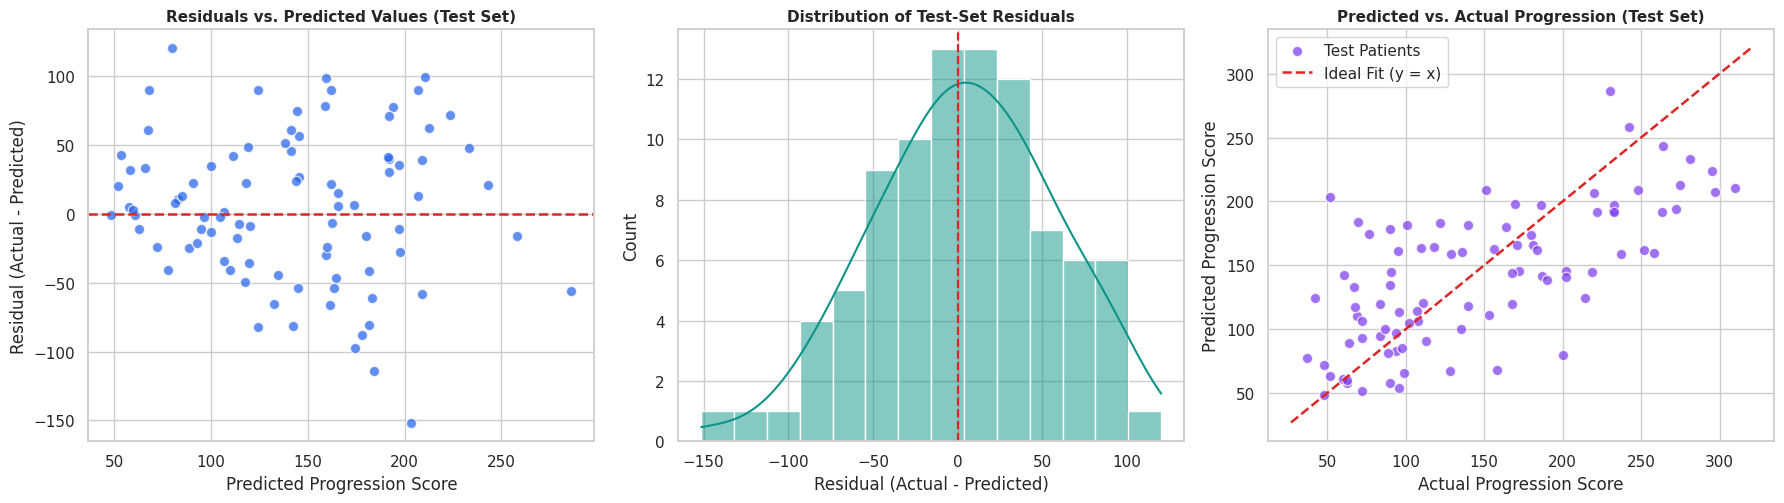

Residual Skewness      : -0.2215
Shapiro-Wilk Normality : W = 0.9928, p-value = 0.9135


In [6]:
residuals = y_test.values - y_pred_clean

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# 1. Residuals vs Predicted
axes[0].scatter(y_pred_clean, residuals, alpha=0.72, color='#2563eb', edgecolors='white', s=55)
axes[0].axhline(0, color='#dc2626', linestyle='--', linewidth=1.8)
axes[0].set_title("Residuals vs. Predicted Values (Test Set)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Predicted Progression Score")
axes[0].set_ylabel("Residual (Actual - Predicted)")

# 2. Residual Histogram + KDE
sns.histplot(residuals, bins=14, kde=True, color='#0d9488', ax=axes[1], edgecolor='white')
axes[1].axvline(0, color='#dc2626', linestyle='--', linewidth=1.6)
axes[1].set_title("Distribution of Test-Set Residuals", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Residual (Actual - Predicted)")
axes[1].set_ylabel("Count")

# 3. Predicted vs Actual with Ideal 45-Degree Line
min_v = min(y_test.min(), y_pred_clean.min()) - 10
max_v = max(y_test.max(), y_pred_clean.max()) + 10
axes[2].scatter(y_test, y_pred_clean, alpha=0.72, color='#7c3aed', edgecolors='white', s=55, label='Test Patients')
axes[2].plot([min_v, max_v], [min_v, max_v], color='#dc2626', linestyle='--', linewidth=1.8, label='Ideal Fit (y = x)')
axes[2].set_title("Predicted vs. Actual Progression (Test Set)", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Actual Progression Score")
axes[2].set_ylabel("Predicted Progression Score")
axes[2].legend()

plt.tight_layout()
plt.show()

shapiro_stat, shapiro_p = stats.shapiro(residuals)
print(f"Residual Skewness      : {stats.skew(residuals):.4f}")
print(f"Shapiro-Wilk Normality : W = {shapiro_stat:.4f}, p-value = {shapiro_p:.4f}")